In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
X = df[["SALES", "QUANTITYORDERED"]].dropna()

In [5]:
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

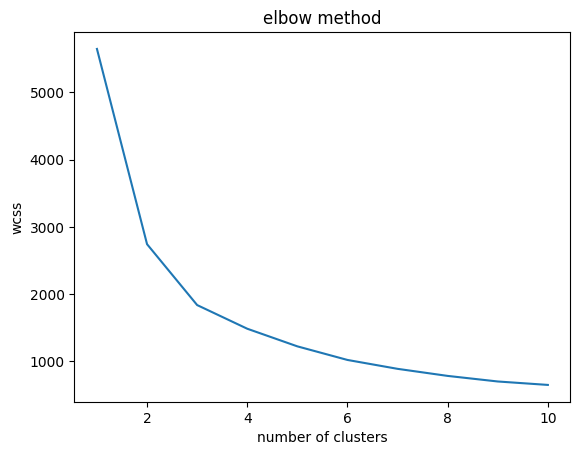

In [6]:
wcss = []

for k in range( 1 , 11):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    
plt.plot(range(1,11),wcss)
plt.xlabel("number of clusters")
plt.ylabel("wcss")
plt.title("elbow method")
plt.show()

In [7]:
kmeans = KMeans(n_clusters = 3)
df["Cluster"] = kmeans.fit_predict(X_scaled)


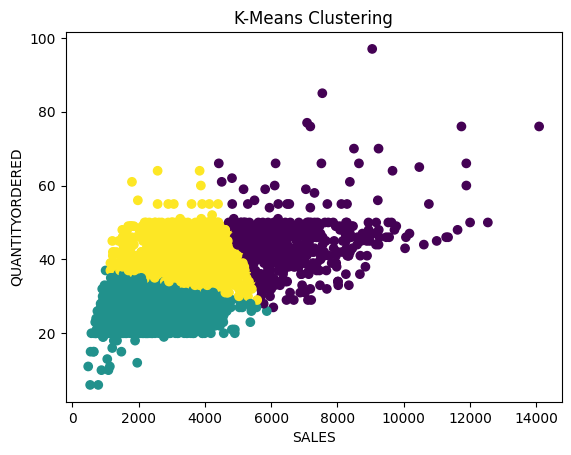

In [8]:
plt.scatter(X["SALES"],X["QUANTITYORDERED"],c = df["Cluster"])
plt.xlabel('SALES')
plt.ylabel('QUANTITYORDERED')
plt.title('K-Means Clustering')
plt.show()